# Menu Intelligence

# Business Questions

- Which products sell the most?
- Which products generate the most revenue and gross profit?
- Which menu categories perform best?
- Which products have high popularity but low profitability, or the reverse?
- Which products should the manager promote, improve, reprice, or consider removing?

# 1. Import Libraries

In [1]:
# ============================================================
# IMPORTS AND PROJECT PATHS
# ============================================================

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

# 2. Project Paths and Data Loading

In [2]:
# ============================================================
# PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path("..")

DATA_DIR = PROJECT_ROOT / "data"
DATA_CLEAN_DIR = PROJECT_ROOT / "data_clean"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
METADATA_DIR = PROJECT_ROOT / "metadata"
MODEL_DIR = PROJECT_ROOT / "models"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT.resolve())
print("Data directory:", DATA_DIR.resolve())
print("Clean data directory:", DATA_CLEAN_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())
print("Metadata directory:", METADATA_DIR.resolve())
print("Model directory:", MODEL_DIR.resolve())

# Plot style
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Project root:", PROJECT_ROOT.resolve())
print("Clean data:", DATA_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())

# ============================================================
# LOAD CLEANED DATASETS
# ============================================================

orders = pd.read_csv( DATA_CLEAN_DIR / "orders_clean.csv", parse_dates=["order_datetime"] )

order_items = pd.read_csv( DATA_CLEAN_DIR / "order_items_clean.csv" )

products = pd.read_csv( DATA_CLEAN_DIR / "products_clean.csv" )

print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Products:", products.shape)

Project root: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine
Data directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/data
Clean data directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/data_clean
Output directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/outputs
Metadata directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/metadata
Model directory: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/models
Project root: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine
Clean data: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/data
Output folder: /Users/pansupari/Desktop/Chapter 17 Final Project/RestroDine/outputs
Orders: (56088, 8)
Order items: (220112, 8)
Products: (30, 6)


# 3. Explore the data

In [3]:
# ============================================================
# INSPECT DATASETS
# ============================================================

print("Orders")
display(orders.head())

print("Order Items")
display(order_items.head())

print("Products")
display(products.head())

Orders


,order_id,customer_id,order_datetime,order_date,order_type,meal_period,order_total,party_size
0,O000001,NaN,2024-01-01 11:46:54,2024-01-01,Dine-in,Lunch,43.80,3
1,O000002,C01367,2024-01-01 12:14:15,2024-01-01,Dine-in,Lunch,34.10,2
2,O000003,NaN,2024-01-01 12:19:10,2024-01-01,Dine-in,Lunch,14.90,1
3,O000004,C01716,2024-01-01 12:20:54,2024-01-01,Takeaway,Lunch,12.90,1
4,O000005,C01866,2024-01-01 12:26:49,2024-01-01,Takeaway,Lunch,23.40,1


Order Items


,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total,promotion_id
0,OI0000001,O000001,P001,1,9.90,0,9.90,NaN
1,OI0000002,O000001,P004,1,12.50,0,12.50,NaN
2,OI0000003,O000001,P011,1,14.90,0,14.90,NaN
3,OI0000004,O000001,P027,1,3.70,0,3.70,NaN
4,OI0000005,O000001,P030,1,2.80,0,2.80,NaN


Products


,product_id,category,product_name,selling_price,product_cost,active
0,P001,Pizza,Margherita,9.90,2.48,1
1,P002,Pizza,Salami,11.50,3.11,1
2,P003,Pizza,Prosciutto,12.90,3.74,1
3,P004,Pizza,Diavola,12.50,3.25,1
4,P005,Pizza,Quattro Formaggi,12.90,3.61,1


# 4. Data validation

In [4]:
# ============================================================
# DATA VALIDATION
# ============================================================

required_orders = {
    "order_id",
    "order_datetime"
}

required_items = {
    "order_id",
    "product_id",
    "quantity",
    "unit_price",
    "discount_pct",
    "line_total"
}

required_products = {
    "product_id",
    "product_name",
    "category",
    "selling_price",
    "product_cost"
}

assert required_orders.issubset(orders.columns), (
    f"Missing orders columns: {required_orders - set(orders.columns)}"
)

assert required_items.issubset(order_items.columns), (
    f"Missing order_items columns: {required_items - set(order_items.columns)}"
)

assert required_products.issubset(products.columns), (
    f"Missing products columns: {required_products - set(products.columns)}"
)

# Check duplicate keys
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
print("Duplicate product IDs:", products["product_id"].duplicated().sum())

if "order_item_id" in order_items.columns:
    print(
        "Duplicate order item IDs:",
        order_items["order_item_id"].duplicated().sum()
    )

# Check missing values in essential columns
print("\nMissing values in orders:")
display(orders[["order_id", "order_datetime"]].isna().sum())

print("\nMissing values in order items:")
display(
    order_items[
        ["order_id", "product_id", "quantity", "unit_price", "line_total"]
    ].isna().sum()
)

print("\nMissing values in products:")
display(
    products[
        ["product_id", "product_name", "category", "selling_price", "product_cost"]
    ].isna().sum()
)

# Check invalid numeric values
print("\nInvalid quantities:", (order_items["quantity"] <= 0).sum())
print("Negative line totals:", (order_items["line_total"] < 0).sum())
print("Negative product costs:", (products["product_cost"] < 0).sum())
print("Negative selling prices:", (products["selling_price"] < 0).sum())

# Check foreign key consistency
missing_order_ids = ~order_items["order_id"].isin(orders["order_id"])
missing_product_ids = ~order_items["product_id"].isin(products["product_id"])

print("\nOrder items with missing order:", missing_order_ids.sum())
print("Order items with missing product:", missing_product_ids.sum())

assert not missing_order_ids.any(), "Some order items have no matching order."
assert not missing_product_ids.any(), "Some order items have no matching product."

print("\nBasic validation completed.")

Duplicate order IDs: 0
Duplicate product IDs: 0
Duplicate order item IDs: 0

Missing values in orders:


order_id          0
order_datetime    0
dtype: int64


Missing values in order items:


order_id      0
product_id    0
quantity      0
unit_price    0
line_total    0
dtype: int64


Missing values in products:


product_id       0
product_name     0
category         0
selling_price    0
product_cost     0
dtype: int64


Invalid quantities: 0
Negative line totals: 0
Negative product costs: 0
Negative selling prices: 0

Order items with missing order: 0
Order items with missing product: 0

Basic validation completed.


# 5. Prepare the menu analysis dataset

In [5]:
# ============================================================
# PREPARE MENU ANALYSIS DATASET
# ============================================================

# Keep the relevant product attributes
product_columns = [
    "product_id",
    "product_name",
    "category",
    "selling_price",
    "product_cost"
]

menu_data = order_items.merge(
    products[product_columns],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Add order date and order-level information
order_columns = [
    "order_id",
    "order_datetime"
]

menu_data = menu_data.merge(
    orders[order_columns],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Extract date-related features
menu_data["order_date"] = menu_data["order_datetime"].dt.date
menu_data["year"] = menu_data["order_datetime"].dt.year
menu_data["month"] = menu_data["order_datetime"].dt.month
menu_data["month_name"] = menu_data["order_datetime"].dt.strftime("%b")
menu_data["year_month"] = menu_data["order_datetime"].dt.to_period("M").astype(str)
menu_data["weekday"] = menu_data["order_datetime"].dt.day_name()

# Financial calculations
menu_data["revenue"] = menu_data["line_total"]

menu_data["total_product_cost"] = (
    menu_data["quantity"] * menu_data["product_cost"]
)

menu_data["gross_profit"] = (
    menu_data["revenue"] - menu_data["total_product_cost"]
)

menu_data["gross_margin_pct"] = np.where(
    menu_data["revenue"] > 0,
    menu_data["gross_profit"] / menu_data["revenue"] * 100,
    np.nan
)

# Contribution margin per unit, based on actual list price and product cost
menu_data["unit_contribution_margin"] = (
    menu_data["unit_price"] - menu_data["product_cost"]
)

print("Menu analysis dataset:", menu_data.shape)

display(menu_data.head())

Menu analysis dataset: (220112, 24)


,order_item_id,order_id,product_id,quantity,unit_price,discount_pct,line_total,promotion_id,product_name,category,selling_price,product_cost,order_datetime,order_date,year,month,month_name,year_month,weekday,revenue,total_product_cost,gross_profit,gross_margin_pct,unit_contribution_margin
0,OI0000001,O000001,P001,1,9.90,0,9.90,NaN,Margherita,Pizza,9.90,2.48,2024-01-01 11:46:54,2024-01-01,2024,1,Jan,2024-01,Monday,9.90,2.48,7.42,74.95,7.42
1,OI0000002,O000001,P004,1,12.50,0,12.50,NaN,Diavola,Pizza,12.50,3.25,2024-01-01 11:46:54,2024-01-01,2024,1,Jan,2024-01,Monday,12.50,3.25,9.25,74.00,9.25
2,OI0000003,O000001,P011,1,14.90,0,14.90,NaN,Beef Burger,Main Course,14.90,4.62,2024-01-01 11:46:54,2024-01-01,2024,1,Jan,2024-01,Monday,14.90,4.62,10.28,68.99,10.28
3,OI0000004,O000001,P027,1,3.70,0,3.70,NaN,Iced Tea,Drink,3.70,0.74,2024-01-01 11:46:54,2024-01-01,2024,1,Jan,2024-01,Monday,3.70,0.74,2.96,80.00,2.96
4,OI0000005,O000001,P030,1,2.80,0,2.80,NaN,Espresso,Drink,2.80,0.59,2024-01-01 11:46:54,2024-01-01,2024,1,Jan,2024-01,Monday,2.80,0.59,2.21,78.93,2.21


# 6. Overall menu performance KPIs

In [6]:
# ============================================================
# 05. OVERALL MENU PERFORMANCE KPIs
# ============================================================

total_units_sold = menu_data["quantity"].sum()
total_item_revenue = menu_data["revenue"].sum()
total_product_cost = round(menu_data["total_product_cost"].sum(), 2)
total_gross_profit = round(menu_data["gross_profit"].sum(), 2)

overall_gross_margin = round(
    total_gross_profit / total_item_revenue * 100
    if total_item_revenue > 0 else np.nan
, 2)

unique_products_sold = menu_data["product_id"].nunique()
total_menu_products = products["product_id"].nunique()
unique_orders = menu_data["order_id"].nunique()

menu_kpis = pd.DataFrame({
    "Metric": [
        "Total units sold",
        "Total item revenue",
        "Total product cost",
        "Total gross profit",
        "Overall gross margin (%)",
        "Unique products sold",
        "Total products in menu",
        "Orders containing menu items"
    ],
    "Value": [
        total_units_sold,
        total_item_revenue,
        total_product_cost,
        total_gross_profit,
        overall_gross_margin,
        unique_products_sold,
        total_menu_products,
        unique_orders
    ]
})

display(menu_kpis)

print(f"Total item revenue: €{total_item_revenue:,.2f}")
print(f"Total gross profit: €{total_gross_profit:,.2f}")
print(f"Overall gross margin: {overall_gross_margin:.2f}%")

,Metric,Value
0,Total units sold,"250,776.00"
1,Total item revenue,"2,091,837.55"
2,Total product cost,"573,897.12"
3,Total gross profit,"1,517,940.43"
4,Overall gross margin (%),72.56
5,Unique products sold,30.00
6,Total products in menu,30.00
7,Orders containing menu items,"56,088.00"


Total item revenue: €2,091,837.55
Total gross profit: €1,517,940.43
Overall gross margin: 72.56%


Business interpretation: these KPIs provide the overall financial baseline. Revenue alone is not enough to evaluate a menu. A product may sell frequently but contribute relatively little gross profit.

# 7. Product-level performance

Aggregate sales and profitability for each individual product.

In [7]:
# ============================================================
# PRODUCT-LEVEL PERFORMANCE
# ============================================================

product_performance = (
    menu_data
    .groupby(
        ["product_id", "product_name", "category"],
        as_index=False
    )
    .agg(
        quantity_sold=("quantity", "sum"),
        total_revenue=("revenue", "sum"),
        total_product_cost=("total_product_cost", "sum"),
        total_gross_profit=("gross_profit", "sum"),
        average_selling_price=("unit_price", "mean"),
        average_discount_pct=("discount_pct", "mean"),
        order_count=("order_id", "nunique")
    )
)

product_performance["gross_margin_pct"] = np.where(
    product_performance["total_revenue"] > 0,
    product_performance["total_gross_profit"]
    / product_performance["total_revenue"] * 100,
    np.nan
)

product_performance["revenue_share_pct"] = (
    product_performance["total_revenue"]
    / product_performance["total_revenue"].sum() * 100
)

product_performance["profit_share_pct"] = (
    product_performance["total_gross_profit"]
    / product_performance["total_gross_profit"].sum() * 100
)

product_performance = product_performance.sort_values(
    "total_revenue",
    ascending=False
)

display(product_performance.head(10))

,product_id,product_name,category,quantity_sold,total_revenue,total_product_cost,total_gross_profit,average_selling_price,average_discount_pct,order_count,gross_margin_pct,revenue_share_pct,profit_share_pct
10,P011,Beef Burger,Main Course,10402,"153,550.69","48,057.24","105,493.45",14.90,0.92,9620,68.70,7.34,6.95
11,P012,Chicken Schnitzel,Main Course,8971,"141,342.03","47,097.75","94,244.28",15.90,0.91,8397,66.68,6.76,6.21
5,P006,Spaghetti Carbonara,Pasta,10475,"130,140.48","31,425.00","98,715.48",12.50,0.60,9658,75.85,6.22,6.50
0,P001,Margherita,Pizza,12251,"120,626.55","30,382.48","90,244.07",9.90,0.54,11147,74.81,5.77,5.95
12,P013,Grilled Chicken,Main Course,6015,"98,360.46","34,766.70","63,593.76",16.50,0.90,5748,64.65,4.70,4.19
1,P002,Salami,Pizza,8061,"92,172.50","25,069.71","67,102.79",11.50,0.56,7612,72.80,4.41,4.42
7,P008,Tagliatelle Bolognese,Pasta,6970,"89,385.93","25,161.70","64,224.23",12.90,0.57,6607,71.85,4.27,4.23
27,P028,Beer 0.5L,Drink,18907,"83,649.15","18,717.93","64,931.22",4.50,1.79,13630,77.62,4.00,4.28
13,P014,Salmon Fillet,Main Course,4046,"79,781.67","25,773.02","54,008.65",19.90,0.89,3926,67.70,3.81,3.56
28,P029,House Wine,Drink,14657,"79,219.80","15,243.28","63,976.52",5.50,1.78,10932,80.76,3.79,4.21


# 8. Best-selling and weakest-selling products
We compare product popularity using units sold, not revenue. A high-priced product can generate high revenue without being a popular product.

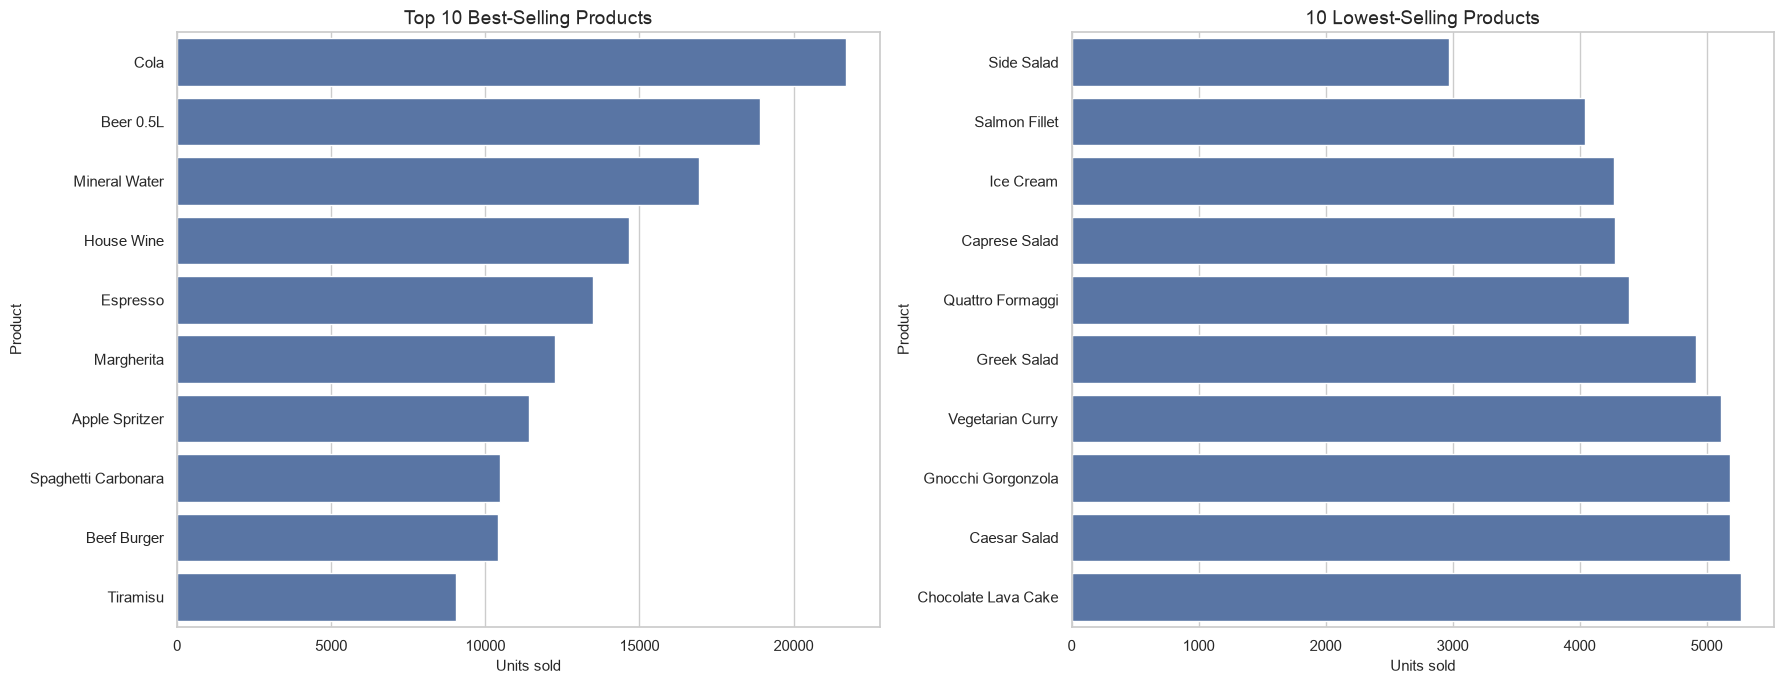

Top-selling products:


,product_name,category,quantity_sold,total_revenue
23,Cola,Drink,21704,"73,725.05"
27,Beer 0.5L,Drink,18907,"83,649.15"
24,Mineral Water,Drink,16935,"52,586.88"
28,House Wine,Drink,14657,"79,219.80"
29,Espresso,Drink,13499,"37,150.12"
0,Margherita,Pizza,12251,"120,626.55"
25,Apple Spritzer,Drink,11412,"43,171.44"
5,Spaghetti Carbonara,Pasta,10475,"130,140.48"
10,Beef Burger,Main Course,10402,"153,550.69"
19,Tiramisu,Dessert,9051,"58,570.32"


Lowest-selling products:


,product_name,category,quantity_sold,total_revenue
18,Side Salad,Salad,2973,"16,320.33"
13,Salmon Fillet,Main Course,4046,"79,781.67"
22,Ice Cream,Dessert,4268,"20,808.71"
17,Caprese Salad,Salad,4276,"40,519.73"
4,Quattro Formaggi,Pizza,4388,"56,274.96"
16,Greek Salad,Salad,4914,"48,516.84"
14,Vegetarian Curry,Main Course,5113,"70,365.96"
9,Gnocchi Gorgonzola,Pasta,5181,"66,462.35"
15,Caesar Salad,Salad,5182,"54,263.37"
21,Chocolate Lava Cake,Dessert,5267,"36,159.86"


In [8]:
# ============================================================
# BEST-SELLING AND WEAKEST-SELLING PRODUCTS
# ============================================================

top_10_products = product_performance.nlargest(
    10, "quantity_sold"
)

bottom_10_products = product_performance.nsmallest(
    10, "quantity_sold"
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(
    data=top_10_products,
    x="quantity_sold",
    y="product_name",
    ax=axes[0]
)

axes[0].set_title("Top 10 Best-Selling Products")
axes[0].set_xlabel("Units sold")
axes[0].set_ylabel("Product")

sns.barplot(
    data=bottom_10_products,
    x="quantity_sold",
    y="product_name",
    ax=axes[1]
)

axes[1].set_title("10 Lowest-Selling Products")
axes[1].set_xlabel("Units sold")
axes[1].set_ylabel("Product")

plt.tight_layout()
plt.show()

print("Top-selling products:")
display(
    top_10_products[
        ["product_name", "category", "quantity_sold", "total_revenue"]
    ]
)

print("Lowest-selling products:")
display(
    bottom_10_products[
        ["product_name", "category", "quantity_sold", "total_revenue"]
    ]
)

# 9. Revenue and gross profit by product

This distinguishes products that generate sales from products that generate profit.

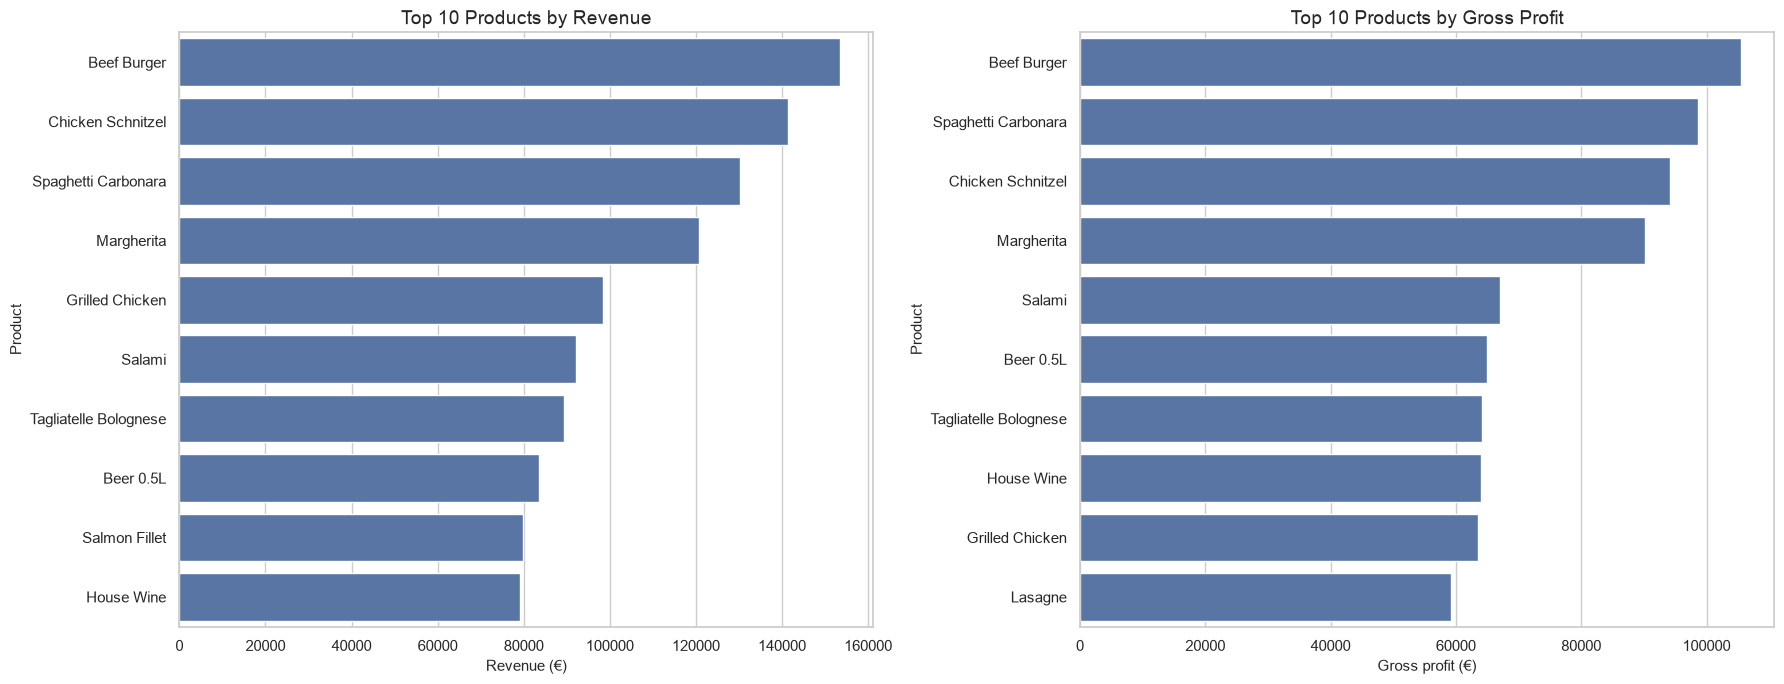

,product_name,quantity_sold,total_revenue,total_gross_profit,gross_margin_pct
10,Beef Burger,10402,"153,550.69","105,493.45",68.70
11,Chicken Schnitzel,8971,"141,342.03","94,244.28",66.68
5,Spaghetti Carbonara,10475,"130,140.48","98,715.48",75.85
0,Margherita,12251,"120,626.55","90,244.07",74.81
12,Grilled Chicken,6015,"98,360.46","63,593.76",64.65
1,Salami,8061,"92,172.50","67,102.79",72.80
7,Tagliatelle Bolognese,6970,"89,385.93","64,224.23",71.85
27,Beer 0.5L,18907,"83,649.15","64,931.22",77.62
13,Salmon Fillet,4046,"79,781.67","54,008.65",67.70
28,House Wine,14657,"79,219.80","63,976.52",80.76


In [9]:
# ============================================================
# PRODUCT REVENUE AND GROSS PROFIT
# ============================================================

top_revenue_products = product_performance.nlargest(
    10, "total_revenue"
)

top_profit_products = product_performance.nlargest(
    10, "total_gross_profit"
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.barplot(
    data=top_revenue_products,
    x="total_revenue",
    y="product_name",
    ax=axes[0]
)

axes[0].set_title("Top 10 Products by Revenue")
axes[0].set_xlabel("Revenue (€)")
axes[0].set_ylabel("Product")

sns.barplot(
    data=top_profit_products,
    x="total_gross_profit",
    y="product_name",
    ax=axes[1]
)

axes[1].set_title("Top 10 Products by Gross Profit")
axes[1].set_xlabel("Gross profit (€)")
axes[1].set_ylabel("Product")

plt.tight_layout()
plt.show()

display(round(
    product_performance[
        [
            "product_name",
            "quantity_sold",
            "total_revenue",
            "total_gross_profit",
            "gross_margin_pct"
        ]
    ], 2))

# 10. Category performance

This helps identify which parts of the menu contribute most to revenue and gross profit.

,category,quantity_sold,total_revenue,total_product_cost,total_gross_profit,unique_products,order_count,gross_margin_pct,revenue_share_pct,profit_share_pct
2,Main Course,34547,"543,400.81","179,879.20","363,521.61",5,26936,66.90,25.98,23.95
3,Pasta,34865,"433,866.70","112,496.85","321,369.85",5,27173,74.07,20.74,21.17
4,Pizza,36189,"414,208.13","111,432.96","302,775.17",5,27943,73.10,19.80,19.95
1,Drink,103917,"393,934.65","80,836.37","313,098.28",7,49163,79.48,18.83,20.63
5,Salad,17345,"159,620.27","47,555.77","112,064.50",4,15010,70.21,7.63,7.38
0,Dessert,23913,"146,806.99","41,695.97","105,111.02",4,19383,71.60,7.02,6.92


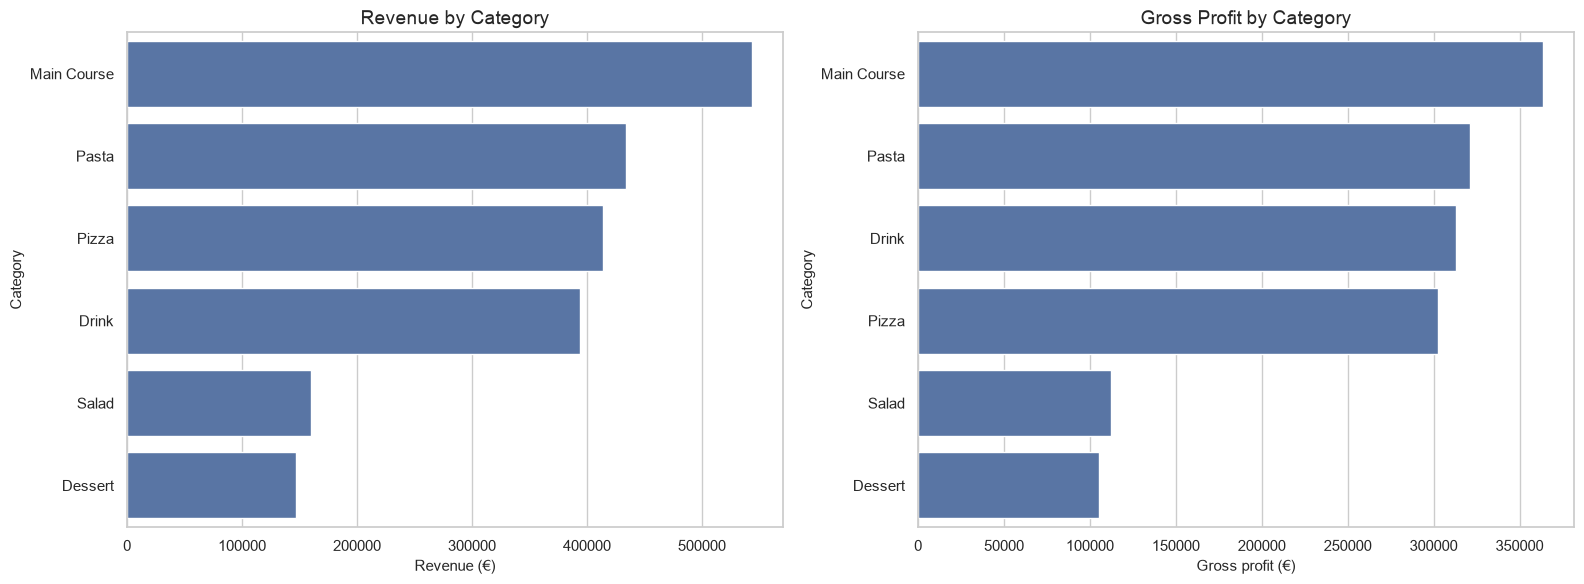

In [10]:
# ============================================================
# CATEGORY PERFORMANCE
# ============================================================

category_performance = (
    menu_data
    .groupby("category", as_index=False)
    .agg(
        quantity_sold=("quantity", "sum"),
        total_revenue=("revenue", "sum"),
        total_product_cost=("total_product_cost", "sum"),
        total_gross_profit=("gross_profit", "sum"),
        unique_products=("product_id", "nunique"),
        order_count=("order_id", "nunique")
    )
)

category_performance["gross_margin_pct"] = np.where(
    category_performance["total_revenue"] > 0,
    category_performance["total_gross_profit"]
    / category_performance["total_revenue"] * 100,
    np.nan
)

category_performance["revenue_share_pct"] = (
    category_performance["total_revenue"]
    / category_performance["total_revenue"].sum() * 100
)

category_performance["profit_share_pct"] = (
    category_performance["total_gross_profit"]
    / category_performance["total_gross_profit"].sum() * 100
)

category_performance = category_performance.sort_values(
    "total_revenue",
    ascending=False
)

display(category_performance)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=category_performance,
    x="total_revenue",
    y="category",
    ax=axes[0],
    order=category_performance.sort_values("total_revenue", ascending=False)["category"]
)

axes[0].set_title("Revenue by Category")
axes[0].set_xlabel("Revenue (€)")
axes[0].set_ylabel("Category")

sns.barplot(
    data=category_performance,
    x="total_gross_profit",
    y="category",
    ax=axes[1],
    order=category_performance.sort_values("total_gross_profit", ascending=False)["category"]
)

axes[1].set_title("Gross Profit by Category")
axes[1].set_xlabel("Gross profit (€)")
axes[1].set_ylabel("Category")

plt.tight_layout()
plt.show()

# 11. Menu performance over time

This reveals whether product sales and revenue change over the two-year period.

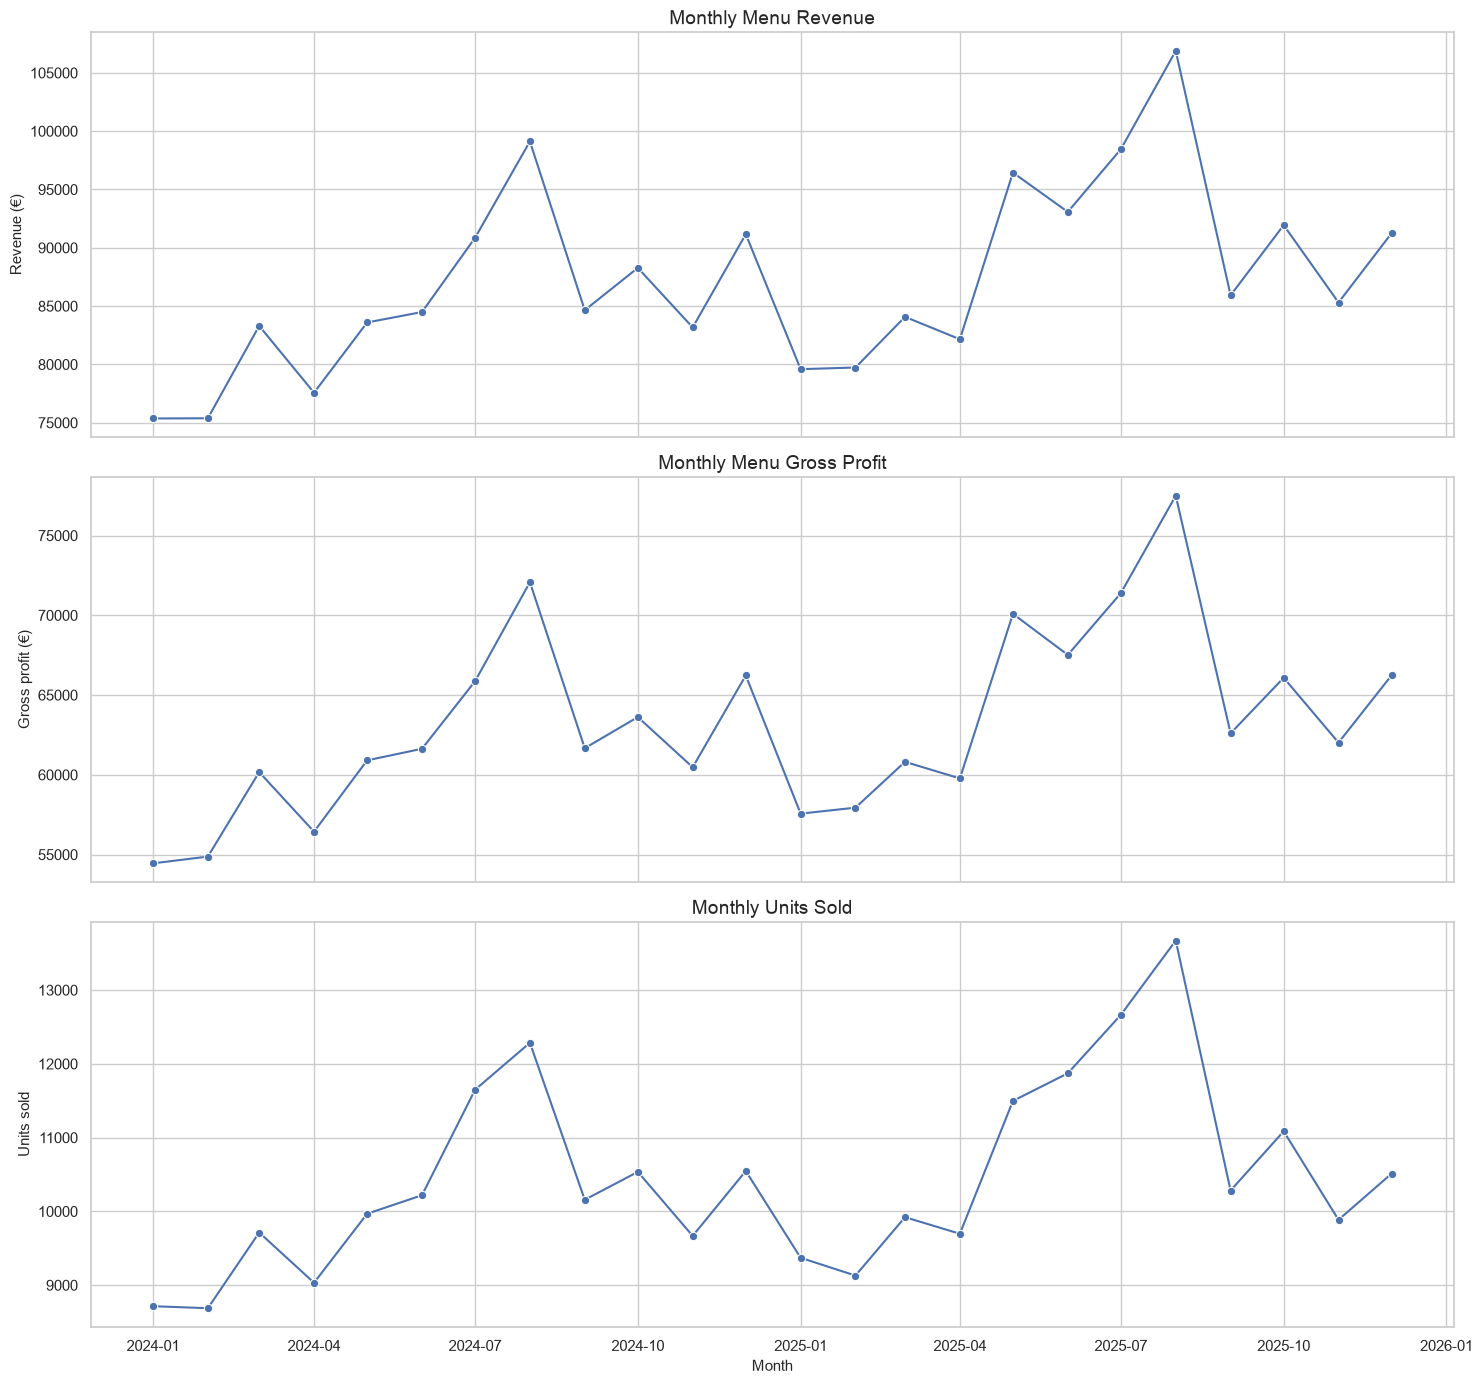

In [11]:
# ============================================================
# MENU PERFORMANCE OVER TIME
# ============================================================

monthly_menu_performance = (
    menu_data
    .groupby("year_month", as_index=False)
    .agg(
        quantity_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

monthly_menu_performance["year_month"] = pd.to_datetime(
    monthly_menu_performance["year_month"]
)

monthly_menu_performance = monthly_menu_performance.sort_values(
    "year_month"
)

fig, axes = plt.subplots(3, 1, figsize=(15, 14), sharex=True)

sns.lineplot(
    data=monthly_menu_performance,
    x="year_month",
    y="revenue",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Monthly Menu Revenue")
axes[0].set_ylabel("Revenue (€)")

sns.lineplot(
    data=monthly_menu_performance,
    x="year_month",
    y="gross_profit",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Monthly Menu Gross Profit")
axes[1].set_ylabel("Gross profit (€)")

sns.lineplot(
    data=monthly_menu_performance,
    x="year_month",
    y="quantity_sold",
    marker="o",
    ax=axes[2]
)

axes[2].set_title("Monthly Units Sold")
axes[2].set_ylabel("Units sold")
axes[2].set_xlabel("Month")

plt.tight_layout()
plt.show()

# 12. Weekday performance
This helps identify which days generate the most product sales and gross profit.

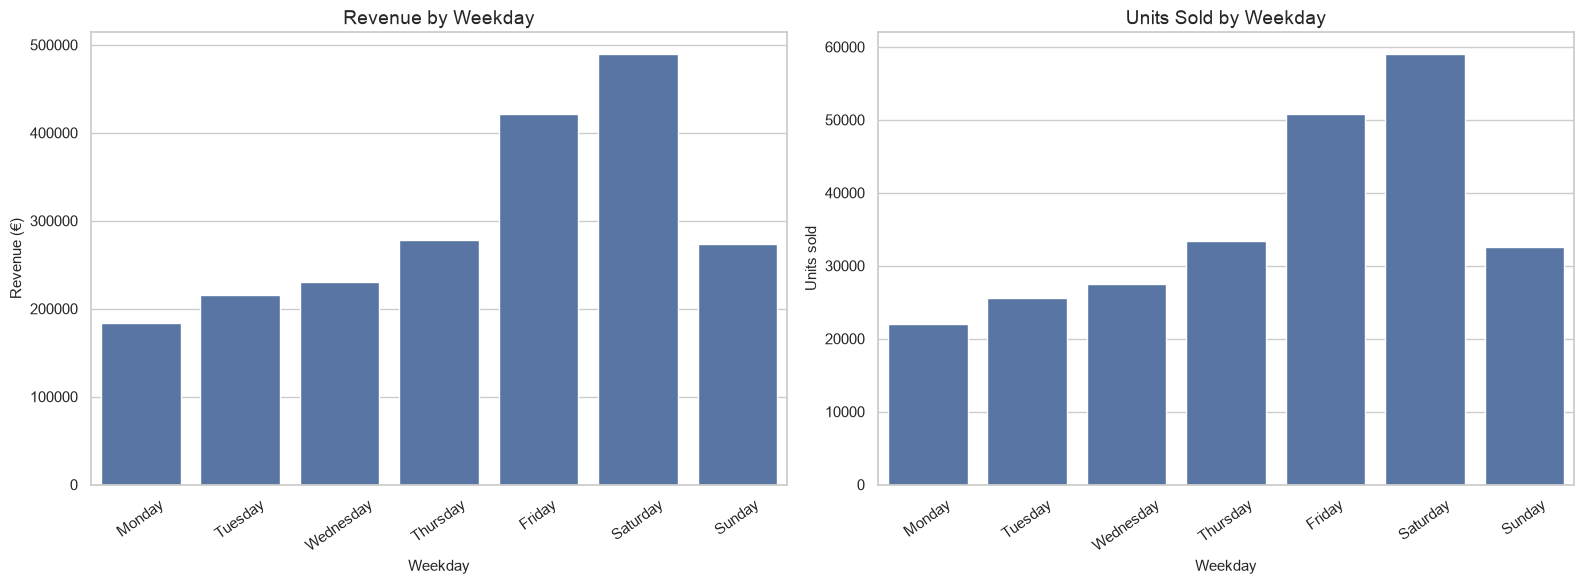

,weekday,quantity_sold,revenue,gross_profit
1,Monday,21957,"183,398.65","133,096.40"
5,Tuesday,25642,"215,174.73","156,102.39"
6,Wednesday,27487,"230,135.28","166,902.38"
4,Thursday,33340,"278,591.59","202,091.04"
0,Friday,50787,"421,811.99","306,289.43"
2,Saturday,59021,"489,567.62","355,501.23"
3,Sunday,32542,"273,157.69","197,957.56"


In [12]:
# ============================================================
# WEEKDAY MENU PERFORMANCE
# ============================================================

weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_performance = (
    menu_data
    .groupby("weekday", as_index=False)
    .agg(
        quantity_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        gross_profit=("gross_profit", "sum")
    )
)

weekday_performance["weekday"] = pd.Categorical(
    weekday_performance["weekday"],
    categories=weekday_order,
    ordered=True
)

weekday_performance = weekday_performance.sort_values("weekday")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=weekday_performance,
    x="weekday",
    y="revenue",
    ax=axes[0]
)

axes[0].set_title("Revenue by Weekday")
axes[0].set_xlabel("Weekday")
axes[0].set_ylabel("Revenue (€)")
axes[0].tick_params(axis="x", rotation=35)

sns.barplot(
    data=weekday_performance,
    x="weekday",
    y="quantity_sold",
    ax=axes[1]
)

axes[1].set_title("Units Sold by Weekday")
axes[1].set_xlabel("Weekday")
axes[1].set_ylabel("Units sold")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

display(weekday_performance)

# 13. Discount analysis

We investigate whether discounted product lines are associated with higher sales volume and how much revenue is generated from discounted lines.

This is descriptive analysis, not a causal experiment. We cannot conclude that discounts caused higher sales from this comparison alone.


,discount_group,line_count,quantity_sold,revenue,gross_profit,average_discount_pct,gross_margin_pct
0,Discounted,25984,31934,"163,073.65","117,909.64",10.63,72.30
1,No discount,194128,218842,"1,928,763.90","1,400,030.79",0.00,72.59


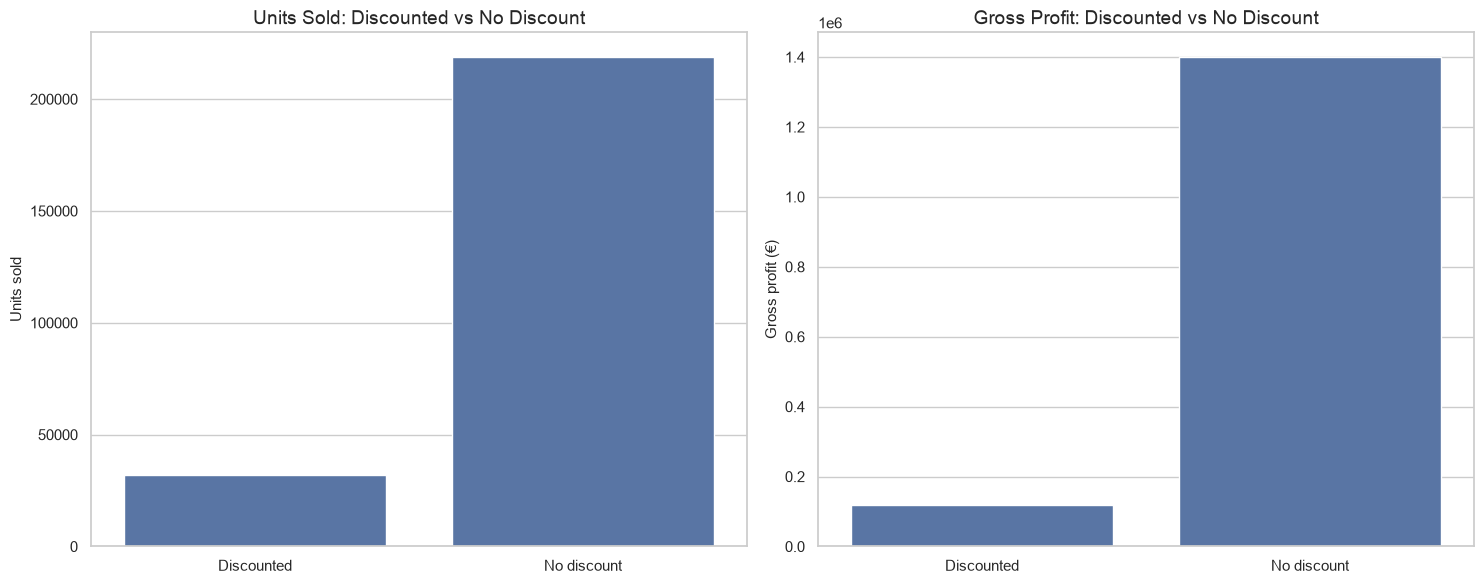

In [13]:
# ============================================================
# DISCOUNT ANALYSIS
# ============================================================

menu_data["discount_group"] = np.where(
    menu_data["discount_pct"] > 0,
    "Discounted",
    "No discount"
)

discount_performance = (
    menu_data
    .groupby("discount_group", as_index=False)
    .agg(
        line_count=("order_id", "count"),
        quantity_sold=("quantity", "sum"),
        revenue=("revenue", "sum"),
        gross_profit=("gross_profit", "sum"),
        average_discount_pct=("discount_pct", "mean")
    )
)

discount_performance["gross_margin_pct"] = np.where(
    discount_performance["revenue"] > 0,
    discount_performance["gross_profit"]
    / discount_performance["revenue"] * 100,
    np.nan
)

display(discount_performance)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=discount_performance,
    x="discount_group",
    y="quantity_sold",
    ax=axes[0]
)

axes[0].set_title("Units Sold: Discounted vs No Discount")
axes[0].set_xlabel("")
axes[0].set_ylabel("Units sold")

sns.barplot(
    data=discount_performance,
    x="discount_group",
    y="gross_profit",
    ax=axes[1]
)

axes[1].set_title("Gross Profit: Discounted vs No Discount")
axes[1].set_xlabel("")
axes[1].set_ylabel("Gross profit (€)")

plt.tight_layout()
plt.show()

# 14. Menu engineering

Menu engineering classifies products using two dimensions:
- Popularity: the product's share of total units sold.
- Profitability: its contribution margin per unit, calculated as average selling price minus product cost.

I use the conventional 70% popularity rule: a product is popular if its sales mix is at least 70% of the average sales mix across the menu. Profitability is assessed against the weighted average contribution margin per unit across all units sold.

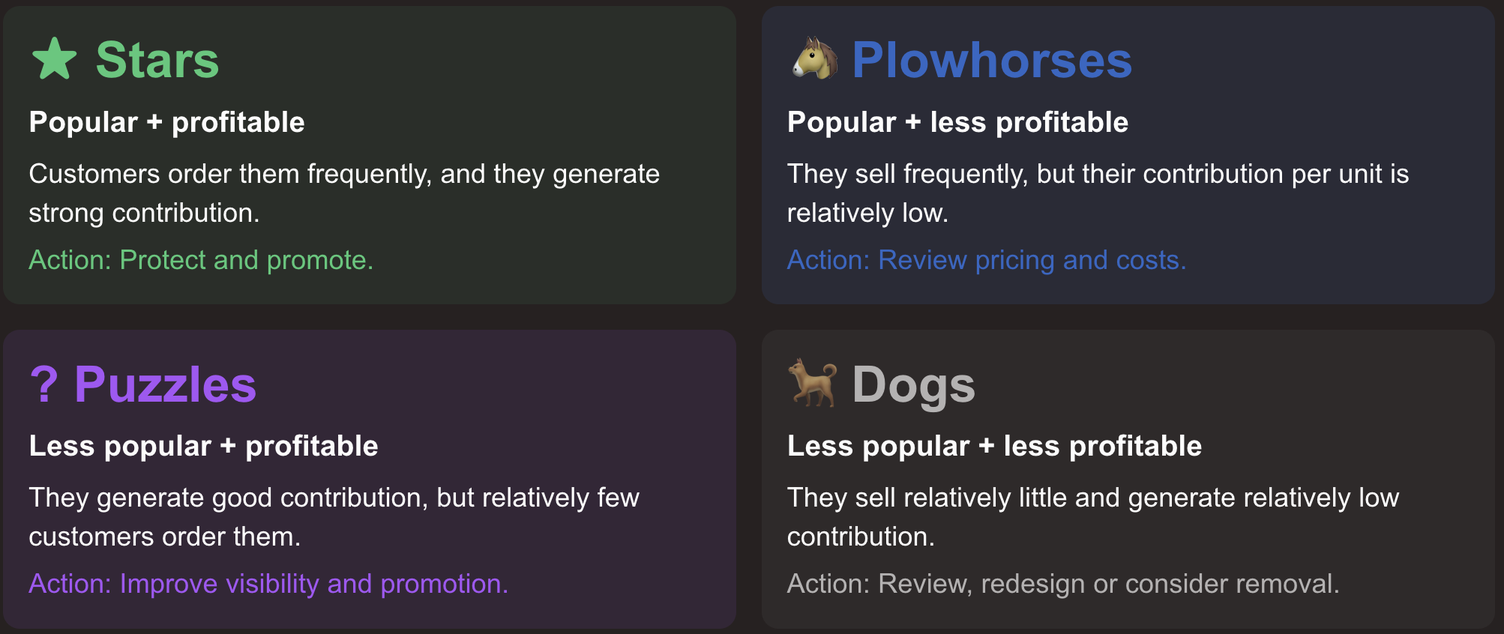

In [14]:
# ============================================================
# MENU ENGINEERING CLASSIFICATION
# ============================================================

# Start with every product in the catalogue, including products
# that may not have sold during the analysis period.
menu_engineering = products[
    [
        "product_id",
        "product_name",
        "category",
        "selling_price",
        "product_cost"
    ]
].copy()

# Aggregate actual product sales
product_sales = (
    menu_data
    .groupby("product_id", as_index=False)
    .agg(
        quantity_sold=("quantity", "sum"),
        total_revenue=("revenue", "sum"),
        total_product_cost=("total_product_cost", "sum"),
        total_gross_profit=("gross_profit", "sum"),
        average_unit_price=("unit_price", "mean")
    )
)

menu_engineering = menu_engineering.merge(
    product_sales,
    on="product_id",
    how="left",
    validate="one_to_one"
)

# Products without sales receive zero sales and financial values
numeric_columns = [
    "quantity_sold",
    "total_revenue",
    "total_product_cost",
    "total_gross_profit"
]

menu_engineering[numeric_columns] = (
    menu_engineering[numeric_columns].fillna(0)
)

# Use actual average selling price when available.
# For products with no sales, retain catalogue selling price.
menu_engineering["average_unit_price"] = (
    menu_engineering["average_unit_price"]
    .fillna(menu_engineering["selling_price"])
)

# Contribution margin per unit
menu_engineering["contribution_margin"] = (
    menu_engineering["average_unit_price"]
    - menu_engineering["product_cost"]
)

# Popularity: each product's share of all units sold
total_units = menu_engineering["quantity_sold"].sum()
number_of_products = len(menu_engineering)

menu_engineering["sales_mix_pct"] = np.where(
    total_units > 0,
    menu_engineering["quantity_sold"] / total_units * 100,
    0
)

# Popularity threshold: 70% of the average product sales mix
average_sales_mix_pct = (
    100 / number_of_products
    if number_of_products > 0 else 0
)

popularity_threshold_pct = 0.70 * average_sales_mix_pct

# Weighted average contribution margin per unit
weighted_average_contribution_margin = (
    menu_engineering["total_gross_profit"].sum() / total_units
    if total_units > 0 else 0
)

# Classify products
menu_engineering["popularity"] = np.where(
    menu_engineering["sales_mix_pct"] >= popularity_threshold_pct,
    "High",
    "Low"
)

menu_engineering["profitability"] = np.where(
    menu_engineering["contribution_margin"]
    >= weighted_average_contribution_margin,
    "High",
    "Low"
)

def classify_menu_item(row):
    if row["popularity"] == "High" and row["profitability"] == "High":
        return "Star"

    elif row["popularity"] == "High" and row["profitability"] == "Low":
        return "Plowhorse"

    elif row["popularity"] == "Low" and row["profitability"] == "High":
        return "Puzzle"

    else:
        return "Dog"


menu_engineering["menu_class"] = menu_engineering.apply(
    classify_menu_item,
    axis=1
)

# Calculate product gross margin percentage
menu_engineering["gross_margin_pct"] = np.where(
    menu_engineering["total_revenue"] > 0,
    menu_engineering["total_gross_profit"]
    / menu_engineering["total_revenue"] * 100,
    np.nan
)

print(f"Number of products: {number_of_products}")
print(f"Total units sold: {total_units:,}")
print(f"Popularity threshold: {popularity_threshold_pct:.2f}%")
print(
    "Weighted average contribution margin: "
    f"€{weighted_average_contribution_margin:.2f}"
)

display(
    menu_engineering.sort_values(
        ["menu_class", "quantity_sold"],
        ascending=[True, False]
    )
)

Number of products: 30
Total units sold: 250,776
Popularity threshold: 2.33%
Weighted average contribution margin: €6.05


,product_id,product_name,category,selling_price,product_cost,quantity_sold,total_revenue,total_product_cost,total_gross_profit,average_unit_price,contribution_margin,sales_mix_pct,popularity,profitability,menu_class,gross_margin_pct
20,P021,Panna Cotta,Dessert,5.90,1.53,5327,"31,268.10","8,150.31","23,117.79",5.90,4.37,2.12,Low,Low,Dog,73.93
21,P022,Chocolate Lava Cake,Dessert,6.90,1.93,5267,"36,159.86","10,165.31","25,994.55",6.90,4.97,2.10,Low,Low,Dog,71.89
22,P023,Ice Cream,Dessert,4.90,1.47,4268,"20,808.71","6,273.96","14,534.75",4.90,3.43,1.70,Low,Low,Dog,69.85
18,P019,Side Salad,Salad,5.50,1.59,2973,"16,320.33","4,727.07","11,593.26",5.50,3.91,1.19,Low,Low,Dog,71.04
23,P024,Cola,Drink,3.50,0.67,21704,"73,725.05","14,541.68","59,183.37",3.50,2.83,8.65,High,Low,Plowhorse,80.28
27,P028,Beer 0.5L,Drink,4.50,0.99,18907,"83,649.15","18,717.93","64,931.22",4.50,3.51,7.54,High,Low,Plowhorse,77.62
24,P025,Mineral Water,Drink,3.20,0.67,16935,"52,586.88","11,346.45","41,240.43",3.20,2.53,6.75,High,Low,Plowhorse,78.42
28,P029,House Wine,Drink,5.50,1.04,14657,"79,219.80","15,243.28","63,976.52",5.50,4.46,5.84,High,Low,Plowhorse,80.76
29,P030,Espresso,Drink,2.80,0.59,13499,"37,150.12","7,964.41","29,185.71",2.80,2.21,5.38,High,Low,Plowhorse,78.56
25,P026,Apple Spritzer,Drink,3.90,0.70,11412,"43,171.44","7,988.40","35,183.04",3.90,3.20,4.55,High,Low,Plowhorse,81.50


# 15. Menu engineering matrix

- X-axis: product popularity.
- Y-axis: contribution margin per unit.
- Vertical line: popularity threshold.
- Horizontal line: average contribution margin.

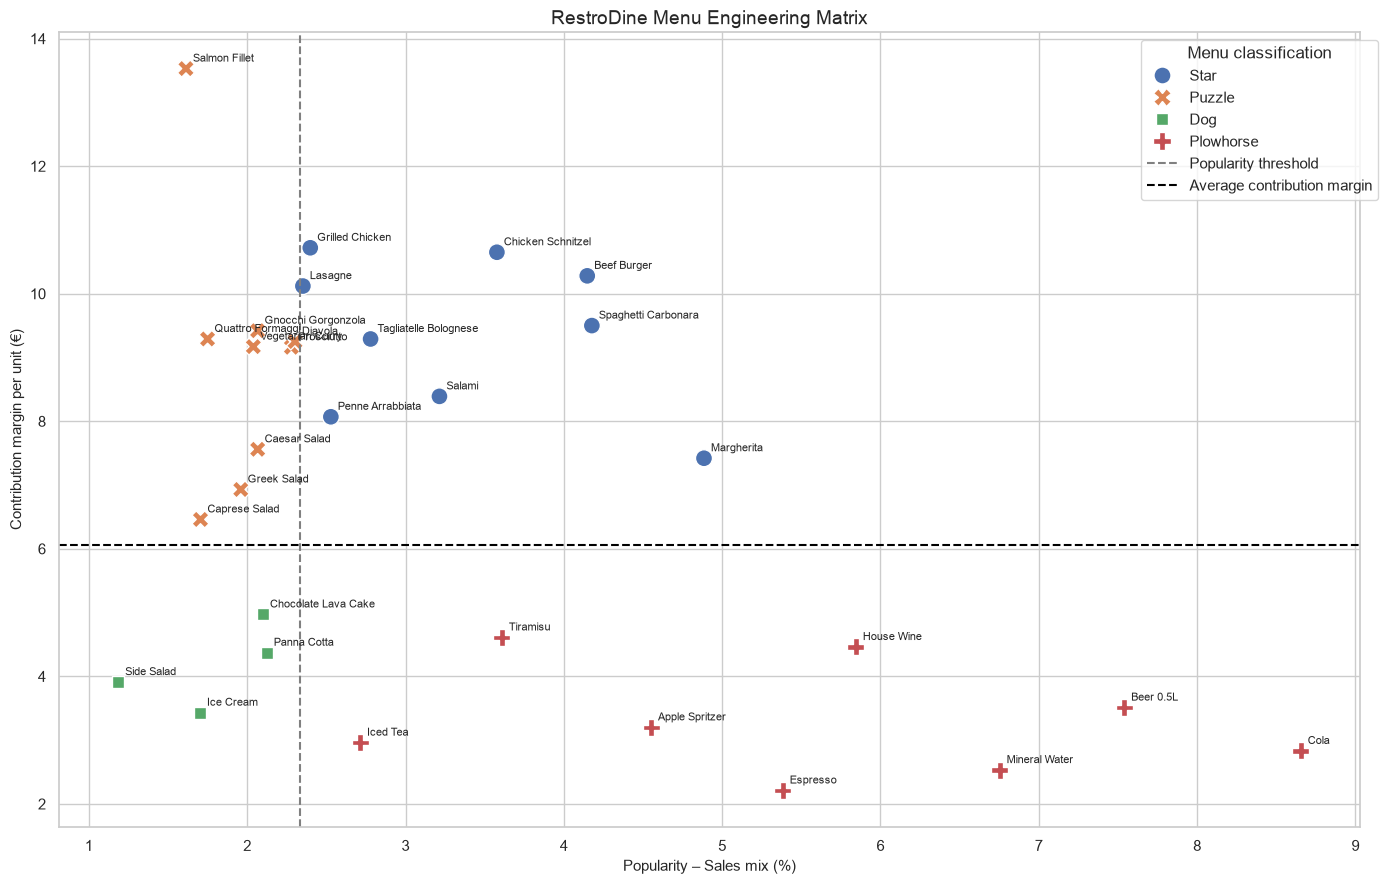

In [15]:
# ============================================================
# MENU ENGINEERING MATRIX
# ============================================================

plt.figure(figsize=(14, 9))

sns.scatterplot(
    data=menu_engineering,
    x="sales_mix_pct",
    y="contribution_margin",
    hue="menu_class",
    style="menu_class",
    s=150
)

plt.axvline(
    x=popularity_threshold_pct,
    linestyle="--",
    color="grey",
    label="Popularity threshold"
)

plt.axhline(
    y=weighted_average_contribution_margin,
    linestyle="--",
    color="black",
    label="Average contribution margin"
)

# Label each product
for _, row in menu_engineering.iterrows():
    plt.annotate(
        row["product_name"],
        (
            row["sales_mix_pct"],
            row["contribution_margin"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title("RestroDine Menu Engineering Matrix")
plt.xlabel("Popularity – Sales mix (%)")
plt.ylabel("Contribution margin per unit (€)")
plt.legend(title="Menu classification", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# 16. Menu engineering summary

Count how many products fall into each classification and calculate their contribution to sales and gross profit.

In [16]:
# ============================================================
# MENU ENGINEERING SUMMARY
# ============================================================

menu_class_summary = (
    menu_engineering
    .groupby("menu_class", as_index=False)
    .agg(
        number_of_products=("product_id", "count"),
        quantity_sold=("quantity_sold", "sum"),
        total_revenue=("total_revenue", "sum"),
        total_gross_profit=("total_gross_profit", "sum")
    )
)

menu_class_summary["product_share_pct"] = (
    menu_class_summary["number_of_products"]
    / number_of_products * 100
)

menu_class_summary["sales_share_pct"] = np.where(
    total_units > 0,
    menu_class_summary["quantity_sold"] / total_units * 100,
    0
)

menu_class_summary["profit_share_pct"] = np.where(
    total_gross_profit != 0,
    menu_class_summary["total_gross_profit"]
    / total_gross_profit * 100,
    0
)

display(menu_class_summary)

,menu_class,number_of_products,quantity_sold,total_revenue,total_gross_profit,product_share_pct,sales_share_pct,profit_share_pct
0,Dog,4,17835,"104,557.00","75,240.35",13.33,7.11,4.96
1,Plowhorse,8,112968,"452,504.97","354,562.21",26.67,45.05,23.36
2,Puzzle,9,44589,"561,319.00","394,522.14",30.00,17.78,25.99
3,Star,9,75384,"973,456.58","693,615.73",30.00,30.06,45.69


# 17. Business recommendations by menu class
Create a manager-friendly table with a suggested action for each product. These are decision prompts, not automatic decisions to remove products.

In [17]:
# ============================================================
# MENU ACTION RECOMMENDATIONS
# ============================================================

menu_actions = {
    "Star": (
        "Protect quality and availability; feature prominently "
        "without unnecessary discounting."
    ),
    "Plowhorse": (
        "Review portion cost, supplier pricing and selling price. "
        "Avoid damaging demand through large price increases."
    ),
    "Puzzle": (
        "Improve menu placement, descriptions and staff recommendations. "
        "Test targeted promotion."
    ),
    "Dog": (
        "Review customer demand, recipe cost and strategic purpose. "
        "Consider redesigning or removing after further review."
    )
}

menu_engineering["recommended_action"] = (
    menu_engineering["menu_class"].map(menu_actions)
)

menu_recommendations = menu_engineering[
    [
        "product_name",
        "category",
        "menu_class",
        "quantity_sold",
        "sales_mix_pct",
        "contribution_margin",
        "gross_margin_pct",
        "total_revenue",
        "total_gross_profit",
        "recommended_action"
    ]
].sort_values(
    ["menu_class", "quantity_sold"],
    ascending=[True, False]
)

display(menu_recommendations)

,product_name,category,menu_class,quantity_sold,sales_mix_pct,contribution_margin,gross_margin_pct,total_revenue,total_gross_profit,recommended_action
20,Panna Cotta,Dessert,Dog,5327,2.12,4.37,73.93,"31,268.10","23,117.79","Review customer demand, recipe cost and strate..."
21,Chocolate Lava Cake,Dessert,Dog,5267,2.10,4.97,71.89,"36,159.86","25,994.55","Review customer demand, recipe cost and strate..."
22,Ice Cream,Dessert,Dog,4268,1.70,3.43,69.85,"20,808.71","14,534.75","Review customer demand, recipe cost and strate..."
18,Side Salad,Salad,Dog,2973,1.19,3.91,71.04,"16,320.33","11,593.26","Review customer demand, recipe cost and strate..."
23,Cola,Drink,Plowhorse,21704,8.65,2.83,80.28,"73,725.05","59,183.37","Review portion cost, supplier pricing and sell..."
27,Beer 0.5L,Drink,Plowhorse,18907,7.54,3.51,77.62,"83,649.15","64,931.22","Review portion cost, supplier pricing and sell..."
24,Mineral Water,Drink,Plowhorse,16935,6.75,2.53,78.42,"52,586.88","41,240.43","Review portion cost, supplier pricing and sell..."
28,House Wine,Drink,Plowhorse,14657,5.84,4.46,80.76,"79,219.80","63,976.52","Review portion cost, supplier pricing and sell..."
29,Espresso,Drink,Plowhorse,13499,5.38,2.21,78.56,"37,150.12","29,185.71","Review portion cost, supplier pricing and sell..."
25,Apple Spritzer,Drink,Plowhorse,11412,4.55,3.20,81.50,"43,171.44","35,183.04","Review portion cost, supplier pricing and sell..."


# 18. Export menu intelligence outputs
These exports can be used later in the Streamlit Menu Performance module. We’ll save the detailed product results, category results, time trends, and menu engineering classifications separately.

In [18]:
# ============================================================
# EXPORT MENU INTELLIGENCE OUTPUTS
# ============================================================

# 1. Overall menu KPIs
menu_kpis.to_csv(
    OUTPUT_DIR / "menu_intelligence_kpis.csv",
    index=False
)

# 2. Product-level performance
product_performance.to_csv(
    OUTPUT_DIR / "menu_product_performance.csv",
    index=False
)

# 3. Category performance
category_performance.to_csv(
    OUTPUT_DIR / "menu_category_performance.csv",
    index=False
)

# 4. Monthly menu performance
monthly_menu_performance.to_csv(
    OUTPUT_DIR / "menu_monthly_performance.csv",
    index=False
)

# 5. Weekday performance
weekday_performance.to_csv(
    OUTPUT_DIR / "menu_weekday_performance.csv",
    index=False
)

# 6. Discount performance
discount_performance.to_csv(
    OUTPUT_DIR / "menu_discount_performance.csv",
    index=False
)

# 7. Menu engineering classification
menu_engineering.to_csv(
    OUTPUT_DIR / "menu_engineering.csv",
    index=False
)

# 8. Manager recommendations
menu_recommendations.to_csv(
    OUTPUT_DIR / "menu_recommendations.csv",
    index=False
)

# 9. Menu engineering class summary
menu_class_summary.to_csv(
    OUTPUT_DIR / "menu_class_summary.csv",
    index=False
)

print("Menu Intelligence exports completed.")

for file in sorted(OUTPUT_DIR.glob("menu_*.csv")):
    print(file.name)

Menu Intelligence exports completed.
menu_category_performance.csv
menu_class_summary.csv
menu_discount_performance.csv
menu_engineering.csv
menu_intelligence_kpis.csv
menu_monthly_performance.csv
menu_product_performance.csv
menu_recommendations.csv
menu_weekday_performance.csv


# 19. Final validation

In [19]:
# ============================================================
# FINAL VALIDATION
# ============================================================

# Revenue reconciliation
item_revenue = menu_data["line_total"].sum()
aggregated_revenue = product_performance["total_revenue"].sum()

# Gross profit reconciliation
item_gross_profit = menu_data["gross_profit"].sum()
aggregated_gross_profit = product_performance["total_gross_profit"].sum()

# Unit reconciliation
item_quantity = menu_data["quantity"].sum()
aggregated_quantity = product_performance["quantity_sold"].sum()

# Classification coverage
classification_count = menu_engineering["menu_class"].notna().sum()

print("Revenue reconciliation:")
print(f"Transaction-level revenue: €{item_revenue:,.2f}")
print(f"Product-level revenue:      €{aggregated_revenue:,.2f}")

print("\nGross profit reconciliation:")
print(f"Transaction-level profit: €{item_gross_profit:,.2f}")
print(f"Product-level profit:     €{aggregated_gross_profit:,.2f}")

print("\nQuantity reconciliation:")
print(f"Transaction-level units: {item_quantity:,}")
print(f"Product-level units:     {aggregated_quantity:,}")

print("\nClassification:")
print(f"Products in catalogue: {number_of_products}")
print(f"Products classified:   {classification_count}")

assert np.isclose(item_revenue, aggregated_revenue)
assert np.isclose(item_gross_profit, aggregated_gross_profit)
assert item_quantity == aggregated_quantity
assert classification_count == number_of_products

print("\nAll final reconciliation checks passed.")

Revenue reconciliation:
Transaction-level revenue: €2,091,837.55
Product-level revenue:      €2,091,837.55

Gross profit reconciliation:
Transaction-level profit: €1,517,940.43
Product-level profit:     €1,517,940.43

Quantity reconciliation:
Transaction-level units: 250,776
Product-level units:     250,776

Classification:
Products in catalogue: 30
Products classified:   30

All final reconciliation checks passed.


Important analytical limitations
A few points matter when interpreting the results:
1. Contribution margin is not net profit. We only subtract the synthetic product cost. Labour and other operating expenses are not allocated to individual menu items.
2. The 70% popularity rule is a classification convention. It is not a statistically validated threshold for this restaurant.
3. Discount comparisons are descriptive. Discounted products may differ from non-discounted products in popularity, category, or timing. This analysis does not establish that discounts caused additional sales.
4. Menu engineering is based on the full 2024–2025 period. A product's classification can change over time, so the manager should also review recent performance before changing the menu.
5. All findings are based on synthetic data. They demonstrate the analytical workflow, not actual restaurant performance.